# Titanic Survival Analysis: Exploratory Data Analysis

## Project Overview

This project explores passenger data from the Titanic disaster to investigate which characteristics were associated with survival.

Using Python, Pandas, Matplotlib and Seaborn, the analysis examines survival rates across passenger demographics and travel characteristics, including sex, passenger class and age.

## Research Question

**What types of passengers were more likely to survive the Titanic disaster?**

## Analytical Approach

1. Assess data structure, data types and missing values.
2. Examine the overall survival rate.
3. Compare survival rates by sex, passenger class and age group.
4. Visualize patterns and document evidence-based findings.

## Dataset

The dataset contains 891 passenger records and 12 variables, including survival status, sex, age, passenger class, fare and embarkation port.

## Tools

- Python
- Pandas
- Matplotlib
- Seaborn
- JupyterLab

In [1]:
import pandas as pd
from pathlib import Path


pd.set_option("display.max_columns", None)

data_path = Path("../data/train.csv")
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()
display(df.isnull().sum().sort_values(ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

In [3]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Summarize missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_summary)

Duplicate rows: 0


,Missing Count,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


In [4]:
# Check the survival target and categorical values
print("Survival counts:")
display(df["Survived"].value_counts().sort_index())

print("\nSex categories:")
display(df["Sex"].value_counts())

print("\nPassenger classes:")
display(df["Pclass"].value_counts().sort_index())

print("\nEmbarkation categories:")
display(df["Embarked"].value_counts(dropna=False))

Survival counts:


Survived
0    549
1    342
Name: count, dtype: int64


Sex categories:


Sex
male      577
female    314
Name: count, dtype: int64


Passenger classes:


Pclass
1    216
2    184
3    491
Name: count, dtype: int64


Embarkation categories:


Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

## 2. Overall Survival Rate

This section establishes the baseline survival rate across all passengers. It provides a reference point for comparing survival outcomes across demographic groups and passenger classes.

The `Survived` variable is binary: `1` represents survival and `0` represents non-survival.



In [5]:
# Calculate passenger survival counts and percentages
survival_counts = df["Survived"].value_counts().sort_index()

survival_summary = pd.DataFrame({
    "Passenger Count": survival_counts,
    "Percentage (%)": (
        survival_counts / len(df) * 100
    ).round(2)
})

survival_summary.index = [
    "Did not survive",
    "Survived"
]

display(survival_summary)

overall_survival_rate = df["Survived"].mean() * 100
print(f"Overall survival rate: {overall_survival_rate:.2f}%")

,Passenger Count,Percentage (%)
Did not survive,549,61.62
Survived,342,38.38


Overall survival rate: 38.38%


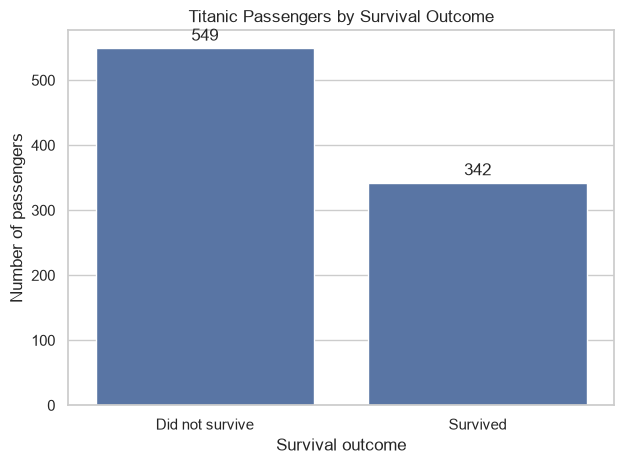

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

survival_plot = (
    df["Survived"]
    .map({0: "Did not survive", 1: "Survived"})
    .value_counts()
    .reindex(["Did not survive", "Survived"])
)

ax = sns.barplot(
    x=survival_plot.index,
    y=survival_plot.values
)

ax.set_title("Titanic Passengers by Survival Outcome")
ax.set_xlabel("Survival outcome")
ax.set_ylabel("Number of passengers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

### Observation

Of the 891 passengers in the dataset, 342 survived and 549 did not. The overall survival rate was approximately 38.4%, meaning that fewer than four in ten passengers in this sample survived.

This baseline provides context for the next stage of analysis, which investigates whether survival rates differed by sex, passenger class and age.

## 3. Survival by Sex

This section compares survival outcomes between male and female passengers. Survival rates are calculated within each group to account for differences in group size.

In [7]:
sex_survival = (
    df.groupby("Sex", observed=True)["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total Passengers",
        "sum": "Survivors",
        "mean": "Survival Rate"
    })
)

sex_survival["Survival Rate (%)"] = (
    sex_survival["Survival Rate"] * 100
).round(2)

display(sex_survival)

,Total Passengers,Survivors,Survival Rate,Survival Rate (%)
Sex,,,,
female,314,233,0.742038,74.20
male,577,109,0.188908,18.89


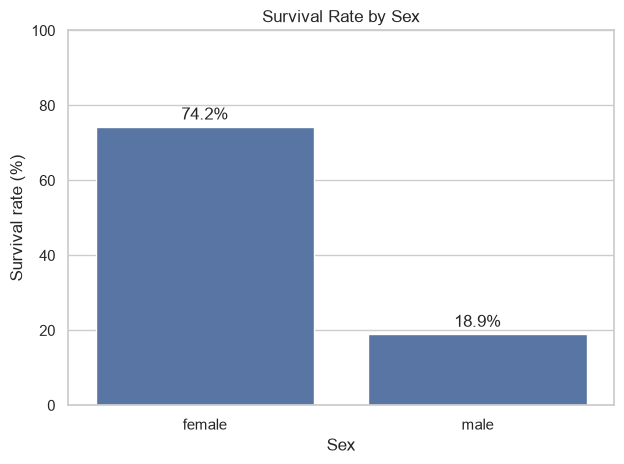

In [8]:
sex_rates = (
    df.groupby("Sex", observed=True)["Survived"]
    .mean()
    .mul(100)
    .reindex(["female", "male"])
)

ax = sns.barplot(
    x=sex_rates.index,
    y=sex_rates.values
)

ax.set_title("Survival Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Survival rate (%)")

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Observation

Female passengers had a survival rate of 74.2%, compared with 18.9% for male passengers. This is a difference of 55.3 percentage points.

The results show a strong association between sex and survival in this dataset. However, this is a descriptive analysis and does not establish that sex alone determined survival.

In [9]:
class_survival = (
    df.groupby("Pclass", observed=True)["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total Passengers",
        "sum": "Survivors",
        "mean": "Survival Rate"
    })
)

class_survival["Survival Rate (%)"] = (
    class_survival["Survival Rate"] * 100
).round(2)

display(class_survival)

,Total Passengers,Survivors,Survival Rate,Survival Rate (%)
Pclass,,,,
1,216,136,0.629630,62.96
2,184,87,0.472826,47.28
3,491,119,0.242363,24.24


## 4. Survival by Passenger Class

This section examines whether survival outcomes differed across the three passenger classes. Passenger class may reflect differences in accommodation and access to resources during the voyage.

Survival rates are calculated within each class so that comparisons account for the different numbers of passengers in each group.

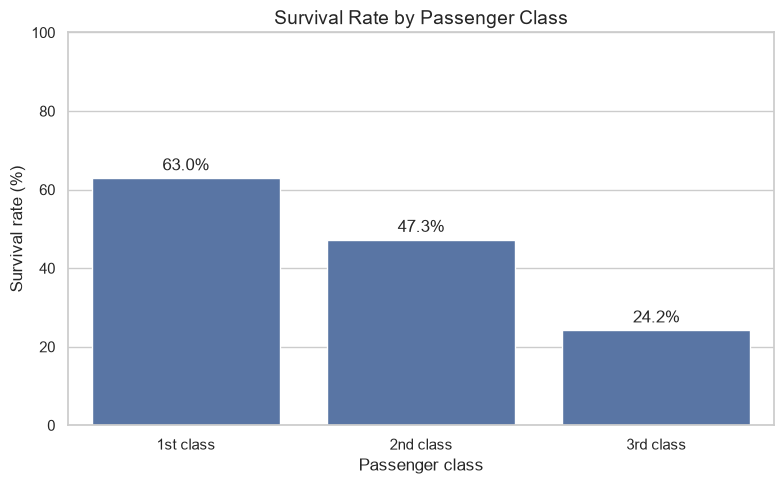

In [10]:
class_rates = (
    df.groupby("Pclass", observed=True)["Survived"]
    .mean()
    .mul(100)
    .reindex([1, 2, 3])
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    x=class_rates.index,
    y=class_rates.values,
    ax=ax
)

ax.set_title("Survival Rate by Passenger Class", fontsize=14)
ax.set_xlabel("Passenger class")
ax.set_ylabel("Survival rate (%)")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["1st class", "2nd class", "3rd class"])
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

### Observation

Survival rates declined across passenger classes. First-class passengers had the highest survival rate at 62.96%, followed by second-class passengers at 47.28%. Third-class passengers had the lowest rate at 24.24%.

The difference between first and third class was 38.72 percentage points. This indicates a strong association between passenger class and survival in the dataset. The results are descriptive and do not, on their own, establish causation.

## 5. Survival by Age Group

This section investigates whether survival rates varied across age groups. Because some passengers have missing age values, the age-based comparison uses passengers whose ages are recorded.

Age groups are descriptive categories created for this analysis; they do not imply that passengers within a group had identical circumstances.

In [11]:
# Create age groups without modifying the original Age column
age_df = df.loc[df["Age"].notna()].copy()

age_df["Age Group"] = pd.cut(
    age_df["Age"],
    bins=[0, 12, 18, 35, 60, float("inf")],
    labels=[
        "Child (0–12)",
        "Teenager (13–18)",
        "Young adult (19–35)",
        "Adult (36–60)",
        "Older adult (60+)"
    ],
    include_lowest=True
)

age_survival = (
    age_df.groupby("Age Group", observed=False)["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Passengers",
        "sum": "Survivors",
        "mean": "Survival Rate"
    })
)

age_survival["Survival Rate (%)"] = (
    age_survival["Survival Rate"] * 100
).round(2)

display(age_survival)

,Passengers,Survivors,Survival Rate,Survival Rate (%)
Age Group,,,,
Child (0–12),69,40,0.579710,57.97
Teenager (13–18),70,30,0.428571,42.86
Young adult (19–35),358,137,0.382682,38.27
Adult (36–60),195,78,0.400000,40.00
Older adult (60+),22,5,0.227273,22.73


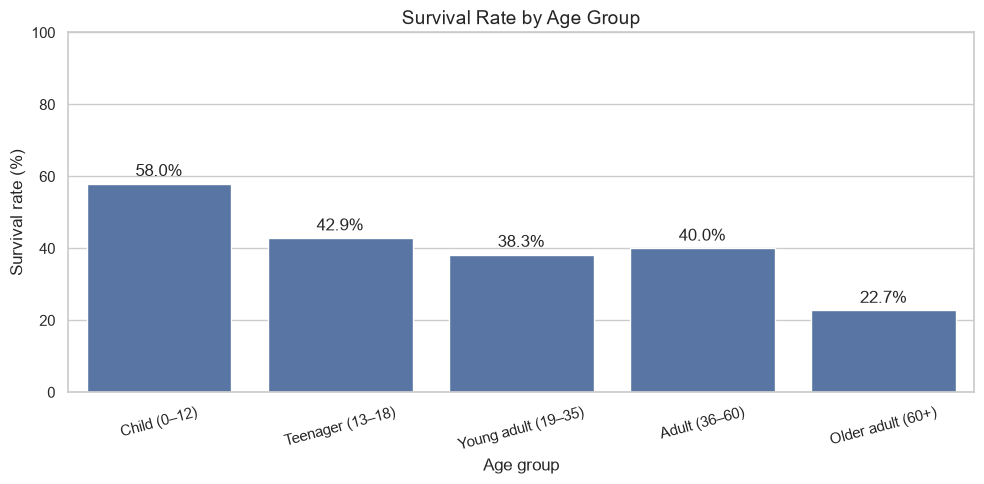

In [12]:
age_rates = (
    age_df.groupby("Age Group", observed=False)["Survived"]
    .mean()
    .mul(100)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=age_rates.index,
    y=age_rates.values,
    ax=ax
)

ax.set_title("Survival Rate by Age Group", fontsize=14)
ax.set_xlabel("Age group")
ax.set_ylabel("Survival rate (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

### Observation

Children aged 12 and under had the highest survival rate among the analyzed age groups, at 57.97%. Teenagers had a survival rate of 42.86%, while young adults and adults had rates of 38.27% and 40.00%, respectively.

Passengers aged over 60 had the lowest observed survival rate at 22.73%. However, this group contained only 22 passengers, so its result should be interpreted cautiously.

This analysis excludes passengers with missing ages; therefore, the findings describe passengers with recorded age values rather than the entire dataset.

## 6. Survival by Sex and Passenger Classm

This section examines survival rates across combinations of sex and passenger class. The comparison helps reveal whether the relationship between sex and survival is consistent across travel classes.

In [15]:
sex_class_rates = pd.pivot_table(
    df,
    values="Survived",
    index="Pclass",
    columns="Sex",
    aggfunc="mean"
) * 100

sex_class_rates.index = [
    "1st class",
    "2nd class",
    "3rd class"
]

display(sex_class_rates.round(2))

Sex,female,male
1st class,96.81,36.89
2nd class,92.11,15.74
3rd class,50.00,13.54


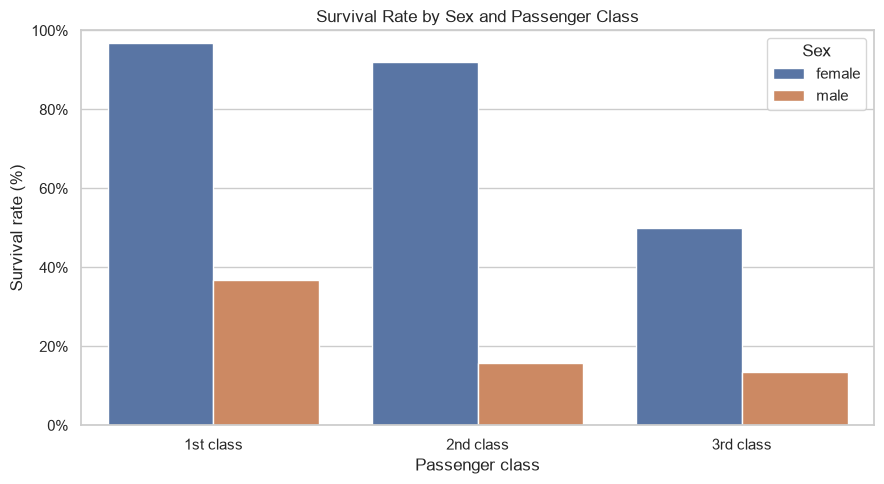

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Sex",
    estimator="mean",
    errorbar=None,
    ax=ax
)

ax.set_title("Survival Rate by Sex and Passenger Class")
ax.set_xlabel("Passenger class")
ax.set_ylabel("Survival rate (%)")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["1st class", "2nd class", "3rd class"])
ax.set_ylim(0, 1)

# Convert the y-axis from proportions to percentages
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])

ax.legend(title="Sex")
plt.tight_layout()
plt.show()